# EDA — BRFSS Diabetes Health Indicators (GenHlth)

Target: `GenHlth`, self-reported general health, 5 classes (1 = Excellent ... 5 = Poor).

## Step 1: Load and sanity-check

In [1]:
import sys; print(sys.executable)

/Users/div/Documents/Projects/Georgia Tech MSCS/Fall 2026/Machine Learning CS7641/slreport/.venv/bin/python3.12


In [2]:
import pandas as pd
from pathlib import Path

DATA = Path("data/diabetes_012_health_indicators_BRFSS2015.csv")
TARGET = "GenHlth"

df = pd.read_csv(DATA)
df.shape

(253680, 22)

In [3]:
df.dtypes.value_counts()

float64    22
Name: count, dtype: int64

In [4]:
print("missing values:", int(df.isna().sum().sum()))
print("exact duplicate rows:", int(df.duplicated().sum()))

missing values: 0
exact duplicate rows: 23899


In [5]:
print("target dtype:", df[TARGET].dtype)
print("target values:", sorted(df[TARGET].unique()))

target dtype: float64
target values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


## Step 2: Declare feature groups

`GenHlth` is the target and must never appear among the predictors. Every other column falls into one of a few types, and the type determines how sensitive a given algorithm is to it:

- **binary** (0/1 health & lifestyle indicators) — thresholds only, scale doesn't matter
- **count** (`MentHlth`, `PhysHlth` — days out of the last 30) — bounded 0-30, right-skewed
- **numeric** (`BMI`) — the one continuous, unbounded-ish feature
- **ordinal** (`Age`, `Education`, `Income`) — ordered integer buckets, not raw units

This split is what justifies, later, statements like "kNN/SVM/NN are scale-sensitive so BMI's wide range matters for them; Decision Trees split on thresholds so it doesn't."

In [6]:
binary = [c for c in df.columns if c != TARGET and set(df[c].dropna().unique()) <= {0.0, 1.0}]
counts = ["MentHlth", "PhysHlth"]
numeric = ["BMI"]
ordinal = ["Age", "Education", "Income"]
FEATURES = [c for c in df.columns if c != TARGET]
other = [c for c in FEATURES if c not in binary + counts + numeric + ordinal]

print(f"binary  ({len(binary)}):", binary)
print("counts  :", counts)
print("numeric :", numeric)
print("ordinal :", ordinal)
print("other   :", other)

assert TARGET not in FEATURES
assert set(binary + counts + numeric + ordinal + other) == set(FEATURES)

binary  (14): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
counts  : ['MentHlth', 'PhysHlth']
numeric : ['BMI']
ordinal : ['Age', 'Education', 'Income']
other   : ['Diabetes_012']


## Step 3: Full-data target distribution

Counts and percentages of `GenHlth` across the full 253,680 rows. If one or two classes dominate, that's the direct evidence for two decisions we'll make later:

- **stratified sampling** — a simple random 20,000-row sample could plausibly under-represent whichever class is rarest here, so we need to preserve these proportions on purpose rather than by luck
- **metric choice** — if a class is small, a model can ignore it almost entirely and still post high Accuracy, which is exactly why Macro-F1 and balanced accuracy (which weight each class equally) are required alongside it

In [7]:
def class_table(y):
    counts = y.value_counts().sort_index()
    return pd.DataFrame({"count": counts, "share_%": (counts / len(y) * 100).round(2)})

full_dist = class_table(df[TARGET])
full_dist

,count,share_%
GenHlth,,
1.0,45299,17.86
2.0,89084,35.12
3.0,75646,29.82
4.0,31570,12.44
5.0,12081,4.76


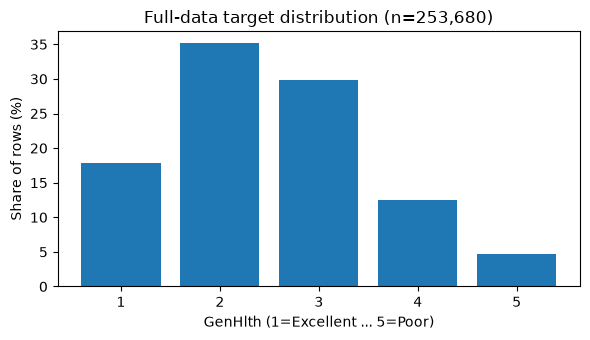

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(full_dist.index.astype(int), full_dist["share_%"])
ax.set_xlabel("GenHlth (1=Excellent ... 5=Poor)")
ax.set_ylabel("Share of rows (%)")
ax.set_title(f"Full-data target distribution (n={len(df):,})")
plt.tight_layout()
plt.savefig("figures/eda_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### Are the duplicate rows concentrated in one class?

From step 1: 23,899 rows (~9.4%) are exact duplicates. Before deciding whether to keep or drop them, check whether they're spread roughly proportionally across `GenHlth` or concentrated in specific classes. If duplicates cluster in one class, dropping them would distort the very distribution above; if they're spread proportionally, dropping them barely changes it either way.

In [9]:
dup_mask = df.duplicated(keep=False)          # flags ALL copies involved in a duplicate group
extra_mask = df.duplicated(keep="first")       # flags only the "extra" copies (what dropping would remove)

dup_dist = class_table(df.loc[dup_mask, TARGET])
extra_dist = class_table(df.loc[extra_mask, TARGET])

compare = pd.DataFrame({
    "full_share_%": full_dist["share_%"],
    "dup_rows_share_%": dup_dist["share_%"],
    "n_extra_copies": extra_dist["count"],
})
compare["share_diff_pp"] = (compare["dup_rows_share_%"] - compare["full_share_%"]).round(2)
compare

,full_share_%,dup_rows_share_%,n_extra_copies,share_diff_pp
GenHlth,,,,
1.0,17.86,40.37,10392,22.51
2.0,35.12,49.44,11548,14.32
3.0,29.82,10.04,1932,-19.78
4.0,12.44,0.14,24,-12.30
5.0,4.76,0.02,3,-4.74


## Step 4: Feature scale/range summary

A compact min/max/mean/std table, tagged by the feature type from step 2. The point isn't the table itself — it's the one interpretive sentence it supports: which features live on a much larger scale than the rest, and which algorithms that actually affects (kNN/SVM/NN are distance- or gradient-based and scale-sensitive; Decision Trees split on thresholds and aren't).

In [10]:
type_of = {**{c: "binary" for c in binary},
           **{c: "count" for c in counts},
           **{c: "numeric" for c in numeric},
           **{c: "ordinal" for c in ordinal},
           **{c: "other" for c in other}}

scale = df[FEATURES].describe().T[["min", "max", "mean", "std"]].round(2)
scale["type"] = scale.index.map(type_of)
scale.sort_values("max", ascending=False)

,min,max,mean,std,type
BMI,12.0,98.0,28.38,6.61,numeric
MentHlth,0.0,30.0,3.18,7.41,count
PhysHlth,0.0,30.0,4.24,8.72,count
Age,1.0,13.0,8.03,3.05,ordinal
Income,1.0,8.0,6.05,2.07,ordinal
Education,1.0,6.0,5.05,0.99,ordinal
Diabetes_012,0.0,2.0,0.30,0.70,other
HeartDiseaseorAttack,0.0,1.0,0.09,0.29,binary
PhysActivity,0.0,1.0,0.76,0.43,binary
Fruits,0.0,1.0,0.63,0.48,binary


## Step 5: Class-conditional patterns

Do feature values actually shift across the 5 `GenHlth` classes, and how? This is the step your hypothesis comes from:

- a **clean, threshold-like** shift (e.g. a feature jumps sharply at one class boundary and flattens elsewhere) favors Decision Trees, which split on exactly that kind of rule
- a **smooth but heavily overlapping** shift across all 5 classes favors margin-based or nonlinear models (RBF SVM, MLP) that can carve a curved boundary through the overlap, rather than a single axis-aligned threshold
- a feature that **barely moves** across classes is weak evidence on its own and says the opposite — no single model gets an easy win from it

We'll look at group means for a handful of features spanning every type from step 2, a full correlation-with-target ranking, and boxplots for the numeric ones so we can actually see the shape of the shift, not just its direction.

In [11]:
key = ["PhysHlth", "MentHlth", "BMI", "Age", "Income", "Education", "DiffWalk", "PhysActivity", "HighBP", "Diabetes_012"]
cond = df.groupby(TARGET)[key].mean().round(2)
cond

,PhysHlth,MentHlth,BMI,Age,Income,Education,DiffWalk,PhysActivity,HighBP,Diabetes_012
GenHlth,,,,,,,,,,
1.0,0.86,1.26,25.77,7.37,6.82,5.38,0.02,0.88,0.20,0.06
2.0,1.53,1.89,27.64,7.80,6.58,5.24,0.06,0.83,0.36,0.16
3.0,3.39,3.07,29.51,8.25,5.84,4.93,0.17,0.72,0.51,0.38
4.0,11.39,6.55,30.69,8.75,4.74,4.58,0.46,0.58,0.65,0.65
5.0,23.52,11.88,30.57,9.00,4.01,4.42,0.75,0.44,0.69,0.79


In [12]:
corr = df[FEATURES].corrwith(df[TARGET]).sort_values()
corr.round(2).to_frame("corr_with_GenHlth")

,corr_with_GenHlth
Income,-0.37
Education,-0.28
PhysActivity,-0.27
Veggies,-0.12
Fruits,-0.10
AnyHealthcare,-0.04
HvyAlcoholConsump,-0.04
Sex,-0.01
CholCheck,0.05
Age,0.15


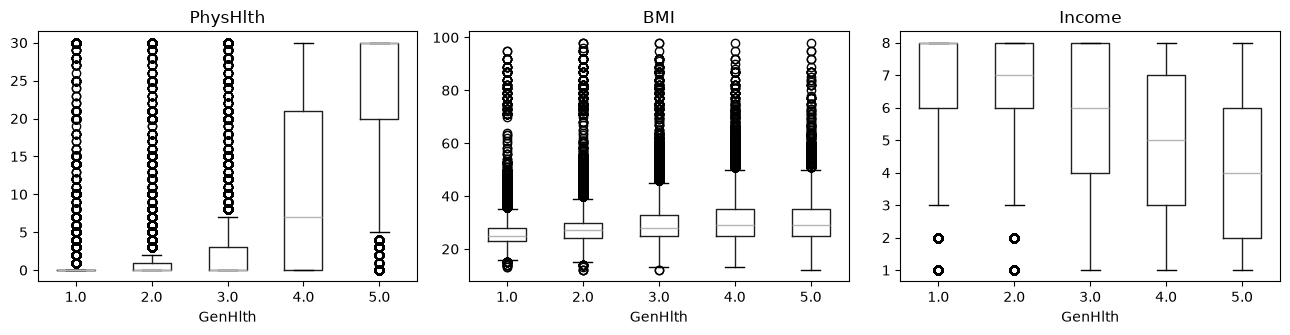

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["PhysHlth", "BMI", "Income"]):
    df.boxplot(column=col, by=TARGET, ax=ax, grid=False)
    ax.set_title(col)
    ax.set_xlabel("GenHlth")
plt.suptitle("")
plt.tight_layout()
plt.savefig("figures/eda_class_conditional.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 6: Feature-feature correlation — only where it answers a question

The FAQ is explicit that correlation isn't required for its own sake, and a big unlabeled heatmap with no interpretation is called out as something to avoid. The specific question worth asking here is: **are any predictors redundant enough that a distance-based model (kNN, SVM) would effectively double-count the same signal?** If two features are highly correlated, a Euclidean/RBF distance implicitly gives that shared signal roughly twice the weight of an independent feature, without that being a deliberate modeling choice.

So instead of the full 21x21 matrix, pull out just the strongest feature-feature pairs (excluding the target, which we already covered in step 5) and interpret only those.

In [14]:
import numpy as np

fcorr = df[FEATURES].corr()
upper_mask = np.triu(np.ones(fcorr.shape, dtype=bool), k=1)
pairs = fcorr.where(upper_mask).stack().sort_values(key=lambda s: s.abs(), ascending=False)
pairs.head(10).round(2).to_frame("corr")

,,corr
PhysHlth,DiffWalk,0.48
Education,Income,0.45
MentHlth,PhysHlth,0.35
HighBP,Age,0.34
DiffWalk,Income,-0.32
HighBP,HighChol,0.30
HighChol,Age,0.27
Diabetes_012,HighBP,0.27
PhysHlth,Income,-0.27
Fruits,Veggies,0.25


## Step 7: Draw the ~20,000-row stratified sample

Stratified on `GenHlth` so each class keeps its full-data proportion by construction, not by luck. We keep the duplicate rows from step 1's finding — dropping them would have disproportionately stripped classes 1-2, which is exactly the distortion stratification is meant to prevent.

After drawing the sample we check two things, not just one:
1. **Does the sample actually preserve the full-data proportions?** (side-by-side table + absolute percentage-point difference)
2. **Is the rarest class still large enough to trust after a further train/test split?** A sample can "preserve proportions" and still leave the smallest class with too few rows to get a stable per-class F1 estimate — those are two different questions.

We don't need to redo every step-4/step-5 table from scratch here; instead we check the single number that would reveal if sampling distorted the feature relationships (max shift in any feature's mean, full vs. sample) as a compact stand-in for "nothing important changed."

In [15]:
from sklearn.model_selection import train_test_split

SEED = 42
N_SAMPLE = 20_000

idx_all = np.arange(len(df))
sample_idx, _ = train_test_split(idx_all, train_size=N_SAMPLE, stratify=df[TARGET], random_state=SEED)
sample = df.iloc[np.sort(sample_idx)].reset_index(drop=True)

Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
sample.to_csv("data/sample_20k.csv", index=False)
np.save("results/sample_row_indices.npy", np.sort(sample_idx))

sample.shape

(20000, 22)

In [16]:
sample_dist = class_table(sample[TARGET])

compare_dist = pd.DataFrame({
    "full_count": full_dist["count"], "full_share_%": full_dist["share_%"],
    "sample_count": sample_dist["count"], "sample_share_%": sample_dist["share_%"],
})
compare_dist["abs_diff_pp"] = (compare_dist["sample_share_%"] - compare_dist["full_share_%"]).abs().round(3)
compare_dist

,full_count,full_share_%,sample_count,sample_share_%,abs_diff_pp
GenHlth,,,,,
1.0,45299,17.86,3571,17.85,0.01
2.0,89084,35.12,7023,35.12,0.00
3.0,75646,29.82,5964,29.82,0.00
4.0,31570,12.44,2489,12.44,0.00
5.0,12081,4.76,953,4.76,0.00


In [ ]:
# projected train/test rows per class after an 80/20 split of the sample
rarest_class = sample_dist["count"].idxmin()
projected = sample_dist.copy()
projected["projected_train_rows"] = (projected["count"] * 0.80).round().astype(int)
projected["projected_test_rows"] = (projected["count"] * 0.20).round().astype(int)
print("rarest class:", rarest_class)
projected

In [ ]:
# max shift in any feature's mean, full data vs. sample
mean_shift = (sample[FEATURES].mean() - df[FEATURES].mean()).abs().sort_values(ascending=False)
mean_shift.head(5).round(4).to_frame("abs_mean_shift")

## Step 8: Hypothesis, grounded in the EDA above

The assignment requires this to be stated *before* tuning and revisited in the conclusion. It needs (1) a predicted ordering/trade-off, (2) a reason tied to a specific EDA observation, and (3) a theory-based mechanism — not a generic "SVM will win" claim.

**What the EDA (step 5) actually showed**, not a generic imbalance story:

- `PhysHlth` (r=0.52 with `GenHlth`) jumps 0.86 → 1.53 → 3.39 → **11.39** → 23.52 across classes 1→5: flat across 1-3, then a sharp step at 4-5. `DiffWalk` shows the same shape: 0.02 → 0.06 → 0.17 → **0.46** → 0.75. Both are **threshold-like**, not linear gradients.
- `Income`, `Education`, `PhysActivity` shift **smoothly and monotonically** but with real overlap between adjacent classes (e.g. Income only drops 6.82→6.58 from class 1→2) — a **smooth, overlapping** shape, not a clean threshold.
- `BMI` rises 25.8→30.7 across classes 1-4 but is *flat* between classes 4 and 5 (30.69 vs. 30.57) — it separates "healthy" from "some problems" but gives near-zero signal for Fair vs. Poor specifically.
- Step 6 found no feature pair above |corr|=0.48 — no evidence of redundant/double-counted signal that would bias a distance-based model.

**Hypothesis:** *A pruned Decision Tree will match or beat a linear-kernel SVM at separating the extreme classes (1 vs. 5), because the strongest predictors (PhysHlth, DiffWalk) separate those classes via sharp, near-threshold jumps that axis-aligned splits exploit directly, while a linear boundary has to compromise across features that barely move in that range. However, an RBF SVM or MLP should outperform the Decision Tree specifically on the adjacent, harder pairs (classes 2 vs. 3, 3 vs. 4), because separation there comes from smooth, overlapping shifts in Income/Education/PhysActivity — a shape a single axis-aligned threshold cannot carve cleanly, but a margin-based or nonlinear model can.* A secondary, testable prediction: because `BMI` plateaus between classes 4 and 5, no model should show strong recall specifically for distinguishing Fair from Poor on BMI-driven splits alone — confusion between those two classes should persist regardless of algorithm.

This is falsifiable in a specific way: if the confusion matrix later shows classes 2/3 and 3/4 as the dominant error pairs (not 1/5), and RBF SVM/MLP win specifically on those adjacent pairs while the Decision Tree is competitive at the extremes, the hypothesis holds. If the Decision Tree instead wins everywhere or nowhere, it's refuted — either result is worth reporting honestly in the conclusion.